# Mapping floods from 13-band Sentinel-2

This notebook trains a ManySeg U-Net on real satellite images, then tests it on a flood it has
never seen. It downloads about 400 MB and takes a few minutes on a GPU. It
also runs on a CPU, but training will be much slower.

The data is [Sen1Floods11](https://github.com/cloudtostreet/Sen1Floods11) (Bonafilia et al.
2020, CC BY 4.0): 512 x 512 px chips at 10 m from 11 flood events, with hand-drawn water labels.

You need `pip install manyseg rasterio matplotlib`.

In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from urllib.request import urlopen, urlretrieve

import manyseg
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import torch
import torch.nn.functional as F
from manyseg import create_model
from manyseg.losses import multiclass_dice
from matplotlib.colors import ListedColormap
from torch.utils.data import DataLoader, Dataset

DATA = Path("data/sen1floods11")  # downloads go here
N_TRAIN, N_TEST, EPOCHS = 120, 40, 40
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

## Get the data

The dataset's public bucket serves each file over plain HTTP, so we only fetch the chips we use.

The splits need one bit of care. The official train and test lists share flood events, so a test
score there is optimistic. The Bolivia event appears only in its own list. It's the fair test of
whether a model works on a flood it hasn't seen, so we keep all 15 of its chips.

In [2]:
BUCKET = "https://storage.googleapis.com/sen1floods11/v1.1"
FOLDER = f"{BUCKET}/data/flood_events/HandLabeled"


def split_names(split):
    url = f"{BUCKET}/splits/flood_handlabeled/flood_{split}_data.csv"
    lines = urlopen(url).read().decode().split()
    return sorted(line.split("_S1Hand")[0] for line in lines)


def read_tif(name, kind):
    path = DATA / kind / f"{name}_{kind}.tif"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{FOLDER}/{kind}/{name}_{kind}.tif", path)
    with rasterio.open(path) as src:
        return src.read().astype(np.float32)


def load(names):
    """Reflectance (N, 13, H, W) and labels (N, H, W): 0 land, 1 water, 255 no data."""
    with ThreadPoolExecutor(8) as pool:
        images = list(pool.map(lambda n: read_tif(n, "S2Hand"), names))
        labels = list(pool.map(lambda n: read_tif(n, "LabelHand"), names))
    y = np.stack(labels)[:, 0]
    return np.nan_to_num(np.stack(images)) / 1e4, np.where(y < 0, 255, y).astype(np.int64)


names = {
    "train": rng.permutation(split_names("train"))[:N_TRAIN].tolist(),
    "test": rng.permutation(split_names("test"))[:N_TEST].tolist(),
    "bolivia": split_names("bolivia"),
}
data = {split: load(chips) for split, chips in names.items()}
for split, (x, y) in data.items():
    print(f"{split:8} {x.shape}, {(y[y != 255] == 1).mean():.1%} water")

train    (120, 13, 512, 512), 10.0% water
test     (40, 13, 512, 512), 9.0% water
bolivia  (15, 13, 512, 512), 15.9% water


## Look at it first

Thirteen bands won't fit on a screen, so we pick three at a time. True colour is what your eye
would see. The false-colour view uses shortwave infrared, which water absorbs, so water turns
almost black and stands out from wet fields and cloud shadow.

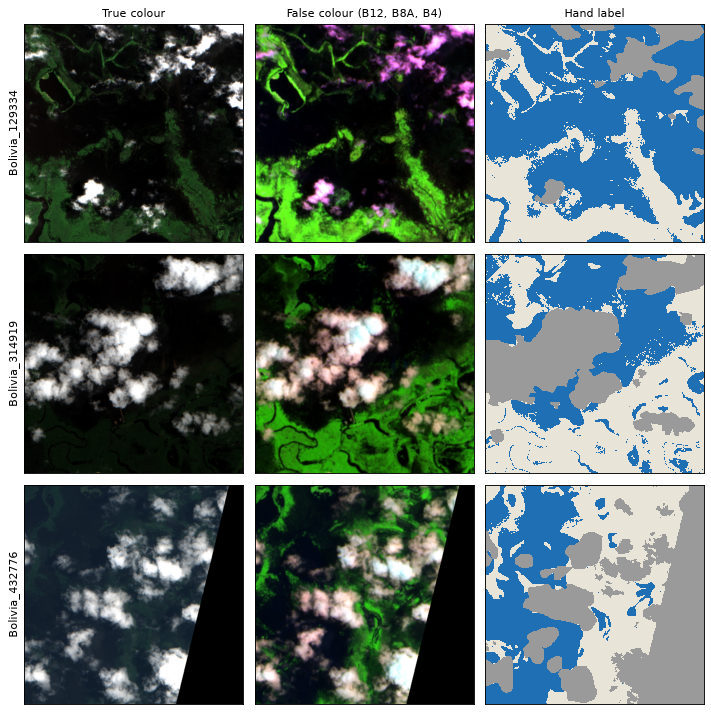

In [3]:
BANDS = ("B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B10", "B11", "B12")
TRUE_COLOUR = [BANDS.index(b) for b in ("B04", "B03", "B02")]
FALSE_COLOUR = [BANDS.index(b) for b in ("B12", "B8A", "B04")]
LABEL_COLOURS = ListedColormap(["#e8e4d8", "#1f6fb4", "#9a9a9a"])  # land, water, no data


def composite(chip, bands):
    """Three bands stretched between their 2nd and 98th percentiles, for display."""
    rgb = chip[bands].transpose(1, 2, 0)
    low, high = np.percentile(rgb, (2, 98), axis=(0, 1))
    return np.clip((rgb - low) / np.maximum(high - low, 1e-6), 0, 1)


def show_label(ax, label):
    ax.imshow(np.where(label == 255, 2, label), cmap=LABEL_COLOURS, vmin=0, vmax=2,
              interpolation="nearest")


x, y = data["bolivia"]
order = np.argsort([-(label == 1).mean() for label in y])[:3]
fig, axes = plt.subplots(len(order), 3, figsize=(9, 3 * len(order)))
for row, i in zip(axes, order):
    row[0].imshow(composite(x[i], TRUE_COLOUR))
    row[1].imshow(composite(x[i], FALSE_COLOUR))
    show_label(row[2], y[i])
    row[0].set_ylabel(names["bolivia"][i])
for ax, title in zip(axes[0], ("True colour", "False colour (B12, B8A, B4)", "Hand label")):
    ax.set_title(title)
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()

## Build the model

One call builds it. `in_channels=13` adapts the ResNet's 3-channel ImageNet stem to 13 bands by
cycling its filters and rescaling them. Each band is normalised with statistics from the
training chips only, so no test data leaks into training.

In [4]:
model = create_model(
    backbone="resnet34",
    pretrained=True,  # ImageNet weights, downloaded once
    in_channels=13,
    num_classes=2,  # land, water
).to(device)
print(model.describe())

mean = data["train"][0].mean((0, 2, 3), keepdims=True)
std = data["train"][0].std((0, 2, 3), keepdims=True) + 1e-6

DenseModel
  params: 24.47M
  returns: Tensor (head 'logits')
  input: pad to multiple of 32
  params by stage: encoders 21.32M, decoders 3.15M, heads 290
inputs
  x: raster, 13 ch
      primary: yes
encoders
  encoder: resnet34 (pretrained)  [21.32M params]
      stem: 13 ch, 'repeat' weights from 3 ch (ch i starts from pretrained filter i % 3, x3/13)
      levels: 64@/2, 64@/4, 128@/8, 256@/16, 512@/32
      divisor: 32
      <- input: x
decoders
  decoder: unet, out_stride 1, width 16  [3.15M params]
      reads: /2, /4, /8, /16, /32
      block channels: (256, 128, 64, 32, 16)
      upsample: nearest
      input_cross: False
      <- encoder (/2, /4, /8, /16, /32)
heads
  logits: segmentation, pixel, 2 ch  [290 params]
      from: decoder
      scale: 1
      resample: /1 feature, none
      returned: as the model's only output
      <- decoder
pretrained weights (fine-tuned weights keep these licences; cite when publishing)
  backbone: timm resnet34.a1_in1k (apache-2.0)
      cite

## Train

This is an ordinary PyTorch loop, because a ManySeg model is a plain `nn.Module`. Each epoch takes
one random 256 px crop per chip, with random flips. The loss is cross-entropy plus Dice, because
water is the smaller class in most chips, and both terms skip the no-data pixels.

epoch  10: loss 0.453


epoch  20: loss 0.289


epoch  30: loss 0.266


epoch  40: loss 0.281


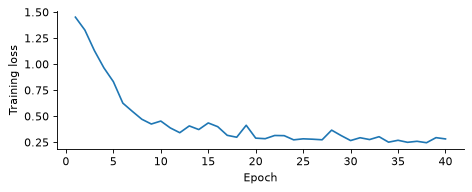

In [5]:
class Crops(Dataset):
    def __init__(self, images, labels, size=256):
        self.images, self.labels, self.size = (images - mean) / std, labels, size

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        top, left = np.random.randint(0, self.images.shape[-1] - self.size + 1, 2)
        window = (..., slice(top, top + self.size), slice(left, left + self.size))
        x, y = self.images[i][window], self.labels[i][window]
        if np.random.rand() < 0.5:
            x, y = x[..., ::-1], y[..., ::-1]
        if np.random.rand() < 0.5:
            x, y = x[..., ::-1, :], y[..., ::-1, :]
        return torch.from_numpy(x.copy()), torch.from_numpy(y.copy())


np.random.seed(0)
loader = DataLoader(Crops(*data["train"]), batch_size=8, shuffle=True, drop_last=True)
optimiser = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
schedule = torch.optim.lr_scheduler.OneCycleLR(optimiser, max_lr=1e-3,
                                               total_steps=EPOCHS * len(loader))
history = []
model.train()
for epoch in range(EPOCHS):
    total = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
            logits = model(images)
            loss = F.cross_entropy(logits, labels, ignore_index=255)
            loss = loss + multiclass_dice(logits, labels, ignore_index=255)
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
        schedule.step()
        total += loss.item()
    history.append(total / len(loader))
    if epoch % 10 == 9 or epoch == EPOCHS - 1:
        print(f"epoch {epoch + 1:3}: loss {history[-1]:.3f}")

fig, ax = plt.subplots(figsize=(6, 2.5))
ax.plot(range(1, EPOCHS + 1), history)
ax.set(xlabel="Epoch", ylabel="Training loss")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

## Test on a flood the model hasn't seen

A ManySeg U-Net accepts any size above its stride, so evaluation uses the whole 512 px chips, not
the 256 px training crops. The score is intersection over union (IoU) of the water class.

In [6]:
@torch.no_grad()
def predict(images, batch_size=4):
    model.eval()
    normalised = torch.from_numpy((images - mean) / std)
    out = []
    for batch in normalised.split(batch_size):
        with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
            out.append(model(batch.to(device)).argmax(1).cpu())
    return torch.cat(out).numpy()


def water_iou(pred, label):
    valid = label != 255
    inter = ((pred == 1) & (label == 1) & valid).sum()
    union = (((pred == 1) | (label == 1)) & valid).sum()
    return inter / union if union else float("nan")


predictions = {split: predict(data[split][0]) for split in ("test", "bolivia")}
for split, pred in predictions.items():
    print(f"water IoU on {split}: {water_iou(pred, data[split][1]):.3f}")

water IoU on test: 0.778
water IoU on bolivia: 0.781


The Bolivia number is the one to quote, because the test chips share flood events with the
training chips. Don't read too much into a close result between the two. Bolivia is one flood and
15 chips, and all of this comes from one seed on part of the data. It's a demonstration, not a
benchmark.

## Where it goes right and wrong

An average hides a lot, so here are the best, middle and worst Bolivia chips with at least 1%
water. In the last column, red is water the model missed and orange is water it invented. Grey
pixels have no label, mostly under cloud, so we can't score the model there and hide its output.

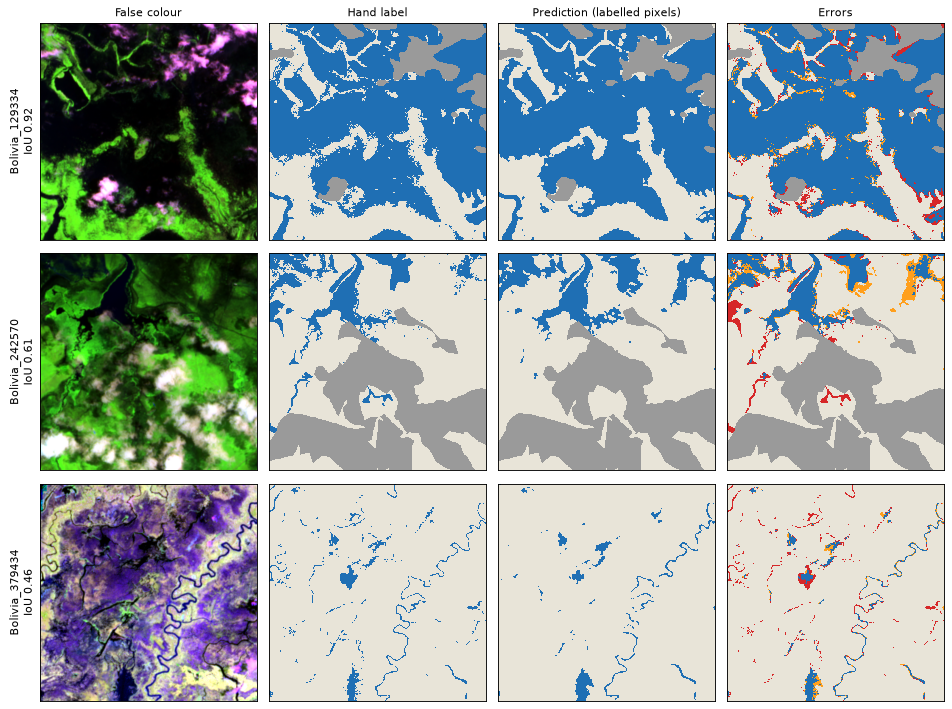

In [7]:
ERROR_COLOURS = ListedColormap(["#e8e4d8", "#1f6fb4", "#d62728", "#ff9f1c", "#9a9a9a"])


def error_map(pred, label):
    out = np.zeros_like(label)  # 0: correct land
    out[(pred == 1) & (label == 1)] = 1  # correct water
    out[(pred == 0) & (label == 1)] = 2  # missed
    out[(pred == 1) & (label == 0)] = 3  # invented
    out[label == 255] = 4
    return out


x, y = data["bolivia"]
pred = predictions["bolivia"]
ranked = sorted((i for i in range(len(y)) if (y[i] == 1).mean() >= 0.01),
                key=lambda i: water_iou(pred[i], y[i]))
picks = [ranked[-1], ranked[len(ranked) // 2], ranked[0]]
fig, axes = plt.subplots(len(picks), 4, figsize=(12, 3 * len(picks)))
for row, i in zip(axes, picks):
    row[0].imshow(composite(x[i], FALSE_COLOUR))
    show_label(row[1], y[i])
    show_label(row[2], np.where(y[i] == 255, 255, pred[i]))
    row[3].imshow(error_map(pred[i], y[i]), cmap=ERROR_COLOURS, vmin=0, vmax=4,
                  interpolation="nearest")
    row[0].set_ylabel(f"{names['bolivia'][i]}\nIoU {water_iou(pred[i], y[i]):.2f}")
titles = ("False colour", "Hand label", "Prediction (labelled pixels)", "Errors")
for ax, title in zip(axes[0], titles):
    ax.set_title(title)
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()

## Save and reload

`manyseg.save` stores the build arguments with the weights, so `manyseg.load` needs no model code.
The file also records how to scale the inputs and how the logits become predictions, because
anyone who uses the model later will need both.

In [8]:
Path("runs").mkdir(exist_ok=True)
path = manyseg.save(
    model, "runs/flood_unet.safetensors",
    # in the GeoTIFFs' raw digital numbers, so the file works on tiles straight from disk
    normalize=[{"type": "zscore", "mean": (mean.ravel() * 1e4).tolist(),
                "std": (std.ravel() * 1e4).tolist()}],
    activations={"logits": "softmax"},
    classes=["land", "water"],
    bands=list(BANDS),
)
reloaded = manyseg.load(path, map_location=device).eval()
with torch.no_grad():
    batch = torch.from_numpy((data["bolivia"][0][:1] - mean) / std).to(device)
    print("same output after reloading:", torch.allclose(model(batch), reloaded(batch)))

same output after reloading: True


## Where to go next

* Train on all 252 chips. Set `N_TRAIN` to 252 and the download grows by about 250 MB.
* Swap the weights. `pretrained="ssl4eo_s2_dino"` with `backbone="resnet50"` loads
  weights pretrained on Sentinel-2, which beat ImageNet on this dataset in
  [E024](https://github.com/DPIRD-DMA/ManySeg/tree/main/experiments/E024_rs_pretrained_weights). They need their own
  normalisation, explained in the
  [API guide](https://github.com/DPIRD-DMA/ManySeg/blob/main/docs/api_design.md).
* Add radar and more outputs, as in
  [the next notebook](02_radar_and_multiple_outputs.ipynb).
* Predict on whole scenes. ManyPred handles images too large for one forward pass.